In [0]:
#importing necessary libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from datetime import datetime
import seaborn as sns
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

In [0]:
df = pd.read_parquet("s3://e-commerce353/gold/user_profiles/")
df.head()

,user_id,total_events,product_views,cart_additions,wishlist_addition,number_of_purchases,total_revenue,conversion_rate,average_order_value
0,U000254,49,23,5,4,5,1184.10,0.2174,236.82
1,U006026,55,32,8,3,6,2941.94,0.1875,490.32
2,U004258,41,24,9,3,1,100.00,0.0417,100.00
3,U005773,53,39,5,3,3,1815.83,0.0769,605.28
4,U007025,46,27,7,0,4,957.81,0.1481,239.45


In [0]:
df.columns.tolist()

['user_id',
 'total_events',
 'product_views',
 'cart_additions',
 'wishlist_addition',
 'number_of_purchases',
 'total_revenue',
 'conversion_rate',
 'average_order_value']

In [0]:
#S3 Paths
silver_path = "s3://e-commerce353/silver/"
gold_path = "s3://e-commerce353/gold/"
df_profiles = pd.read_parquet(f"{gold_path}user_profiles/")
df_orders = pd.read_parquet(f"{silver_path}orders/")
recent_date = df_orders["order_timestamp"].max()
df_last_purchase = (df_orders.groupby("user_id")["order_timestamp"].max().reset_index())
df_last_purchase.rename(columns={"order_timestamp": "last_purchase_date"}, inplace=True)
# calculating recency
df_last_purchase["recency_days"] = (
    recent_date - df_last_purchase["last_purchase_date"]
).dt.days

# merging recency back to user_profile
df_rfm = pd.merge(df_profiles, df_last_purchase[["user_id", "recency_days"]], on="user_id", how="left")

# Users who never ordered get a recency score equal to the max dataset + 1
max_recency = df_rfm["recency_days"].max()
df_rfm["recency_days"] = df_rfm["recency_days"].fillna(max_recency + 30)

# Extract final RFM feature subset
df_rfm_features = df_rfm[["user_id", "recency_days", "number_of_purchases", "total_revenue"]].copy()
df_rfm_features.rename(
    columns={
        "number_of_purchases": "frequency",
        "total_revenue": "monetary",
    },
    inplace=True,
)

print(f"RFM dataset prepared for {len(df_rfm_features):,} users.")


RFM dataset prepared for 10,000 users.


In [0]:
df_orders.columns.tolist()

['order_id',
 'order_timestamp',
 'user_id',
 'product_id',
 'quantity',
 'unit_price',
 'discount',
 'total_amount',
 'ingestion_timestamp',
 'source_system',
 'pipeline_version',
 'order_date']

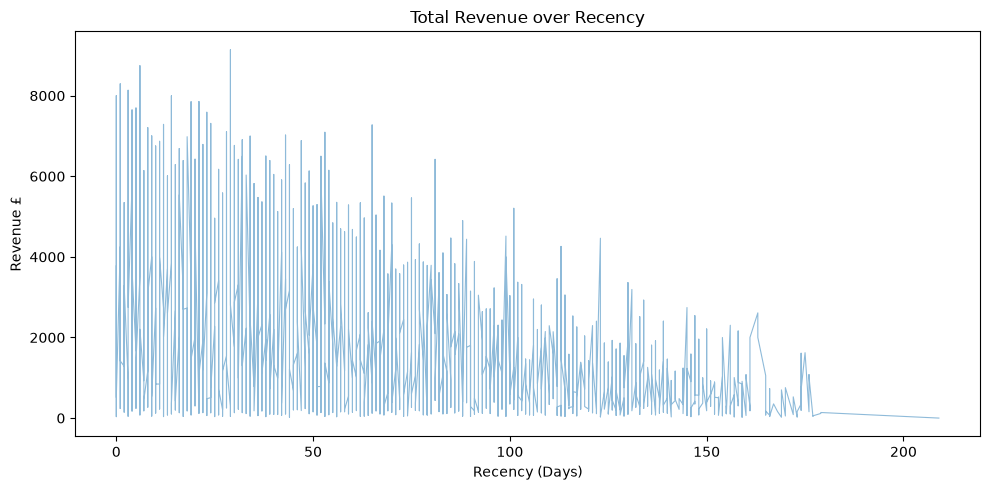

In [0]:
plot_df = df_rfm_features[["recency_days", "monetary"]].sort_values("recency_days")

plt.figure(figsize=(10, 5))
plt.plot(plot_df["recency_days"], plot_df["monetary"], alpha=0.5, linewidth=0.8)
plt.title("Total Revenue over Recency")
plt.xlabel("Recency (Days)")
plt.ylabel("Revenue £")
plt.tight_layout()
plt.show()

In [0]:

#log transformation and nomalization due to frequency and money often have heavily skewed long-tail distributions
df_rfm_features["recency_log"] = np.log1p(df_rfm_features["recency_days"])
df_rfm_features["frequency_log"] = np.log1p(df_rfm_features["frequency"])
df_rfm_features["monetary_log"] = np.log1p(df_rfm_features["monetary"])

# Select columns to scale
X_raw = df_rfm_features[["recency_log", "frequency_log", "monetary_log"]]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

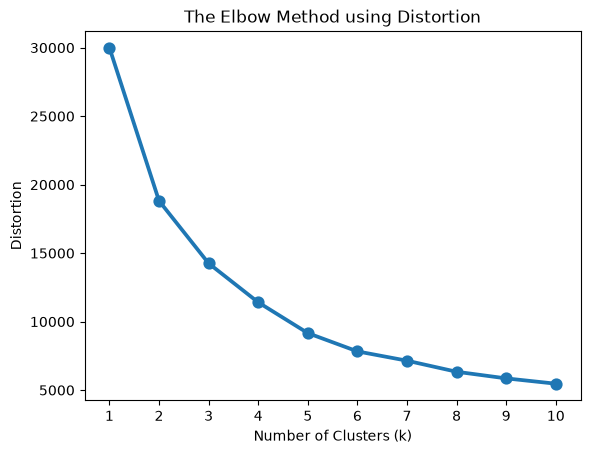

In [0]:
error = {}
for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42)
    model.fit(X_scaled)
    error[k] = model.inertia_

plt.xlabel('Number of Clusters (k)')
plt.ylabel('Distortion')
plt.title('The Elbow Method using Distortion')
sns.pointplot(x=list(error.keys()), y=list(error.values()))
plt.show()

In [0]:
inertias = []
silhouette_scores = []

k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = kmeans.fit_predict(X_scaled)
    
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

print("Inertias:")
for k, inertia in zip(k_values, inertias):
    print(f"K={k}: {inertia:.2f}")

print("\nSilhouette scores:")
for k, score in zip(k_values, silhouette_scores):
    print(f"K={k}: {score:.4f}")

Inertias:
K=2: 18819.49
K=3: 14252.84
K=4: 11323.25
K=5: 9161.86
K=6: 7819.00
K=7: 6966.05
K=8: 6331.64
K=9: 5813.20
K=10: 5409.90

Silhouette scores:
K=2: 0.3622
K=3: 0.3062
K=4: 0.3167
K=5: 0.2927
K=6: 0.2928
K=7: 0.2653
K=8: 0.2663
K=9: 0.2565
K=10: 0.2519


In [0]:
#kmeans clustering
K = 4
kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
df_rfm_features["cluster"] = kmeans.fit_predict(X_scaled)

# Inspecting cluster to name them
cluster_summary = df_rfm_features.groupby("cluster")[
    ["recency_days", "frequency", "monetary"]
].mean()
print("\n Cluster Profiles (Averages)")
print(cluster_summary)


 Cluster Profiles (Averages)
         recency_days  frequency     monetary
cluster                                      
0           60.268788   2.581288   751.983117
1            4.956720   6.123007  2376.450061
2           36.659352   5.745420  2370.799955
3          207.031250   0.046875     1.008906


In [0]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

df_rfm_features["pca1"] = X_pca[:, 0]
df_rfm_features["pca2"] = X_pca[:, 1]

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_rfm_features,
    x="pca1",
    y="pca2",
    hue="cluster",
    palette="viridis",
    alpha=0.7,
)

plt.title("Customer Segmentation Map (K-Means & PCA)", fontsize=14, fontweight="bold")
plt.xlabel("Overall Customer Value & Engagement (PCA 1)", fontsize=12)
plt.ylabel("Recency & Behavioral Pattern (PCA 2)", fontsize=12)

plt.legend(title="Customer Segments", labels=["Casual Shoppers", "VIP Champions", "Loyal Mid-Tier", "Inactive/Outliers"])
plt.tight_layout()
plt.show()
# saving to customer_segment
df_rfm_features.to_parquet("s3://e-commerce353/gold/customer_segments/")
print("\nCustomer segments successfully saved to Gold S3 layer!")


Customer segments successfully saved to Gold S3 layer!
